## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [23]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Geethan Sundaram

**Date:** 10/19/2026

-- Q1 --
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


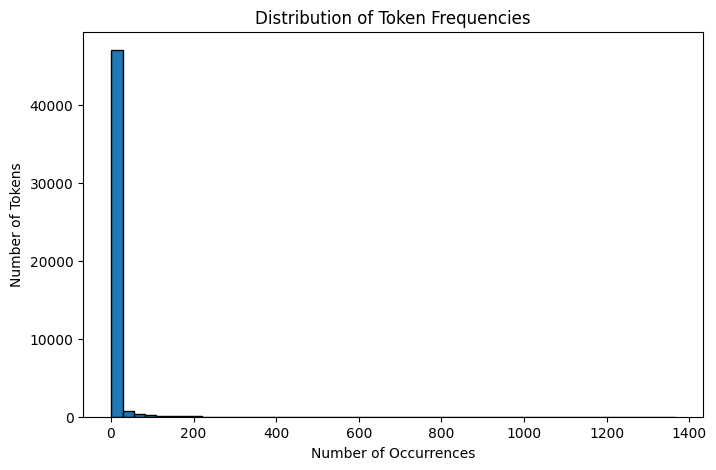

The distribution is extremely right skewed. Most tokens tend to only appear a
few times, while a very trivial number of tokens appear far more often. A large
concentration of tokens are located in the left side of the histogram which a
very long tail towards the right of the histogram. This shows us that certain
words are used far more often than others, even after common words are removed.
A whopping 29,404 unique tokens appeared only one time, while the most frequent
token, 'new', appears 1,365 times.


In [24]:
print("-- Q1 --")

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
import textwrap

# load the token data
with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(token_freq[:10])

counts = list(token_count.values())

# plot the histogram of token frequencies
plt.figure(figsize=(8, 5))
plt.hist(counts, bins=50, edgecolor='black')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.title('Distribution of Token Frequencies')
plt.show()

text = "The distribution is extremely right skewed. Most tokens tend to only appear a few times, while a very trivial number of tokens appear far more often. A large concentration of tokens are located in the left side of the histogram which a very long tail towards the right of the histogram. This shows us that certain words are used far more often than others, even after common words are removed. A whopping 29,404 unique tokens appeared only one time, while the most frequent token, 'new', appears 1,365 times."

print("\n".join(textwrap.wrap(text, width=80)))  

In [25]:
print("-- Q2 --")

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy.sparse import csr_matrix

# Load the data
file_path = Path('data/Phishing_clean.parquet')
if not file_path.exists():
    file_path = Path('Phishing_clean.parquet')

df = pd.read_parquet(file_path)

# split the data into features and target
X = df.drop(columns=['Email Type'])
y = df['Email Type']

# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train rows:', len(X_train))
print('Test rows:', len(X_test))
print('Number of features:', X.shape[1])

# Train a linear regression model
model = LinearRegression()
model.fit(csr_matrix(X_train), y_train)

train_r2 = model.score(csr_matrix(X_train), y_train)
test_r2 = model.score(csr_matrix(X_test), y_test)

print('Training R²:', round(train_r2, 4))
print('Test R²:', round(test_r2, 4))

coefficients = pd.Series(model.coef_, index=X.columns)
top_words = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
)
print('Top 10 tokens by absolute coefficient:')
print(top_words.head(10).round(4))

text = "The training R^2 was 0.7713 and the test R^2 was 0.6424. The model does fit the training data more effectively, so there may be overfitting present. The largest coefficients seemed to be for 'background-image:', 'localized', 'thermal', 'aging', and 'erectile'. The positive coefficients bring the prediction towards phishing (1), while the negative coefficients push it towards normal (0) instead. I did also notice how certain features were pieces of HTML or some kind of formatting rather than genuine words."

print("\n".join(textwrap.wrap(text, width=80)))


-- Q2 --
Train rows: 14907
Test rows: 3727
Number of features: 2711
Training R²: 0.7713
Test R²: 0.6424
Top 10 tokens by absolute coefficient:
background-image:   -1.0160
localized            0.8395
thermal              0.6996
#331f30;             0.6159
#000000;             0.6158
form.                0.5937
aging                0.5867
erectile             0.5385
girlfriend           0.5276
xanaax               0.5164
dtype: float64
The training R^2 was 0.7713 and the test R^2 was 0.6424. The model does fit the
training data more effectively, so there may be overfitting present. The largest
coefficients seemed to be for 'background-image:', 'localized', 'thermal',
'aging', and 'erectile'. The positive coefficients bring the prediction towards
phishing (1), while the negative coefficients push it towards normal (0)
instead. I did also notice how certain features were pieces of HTML or some kind
of formatting rather than genuine words.


-- Q3 --


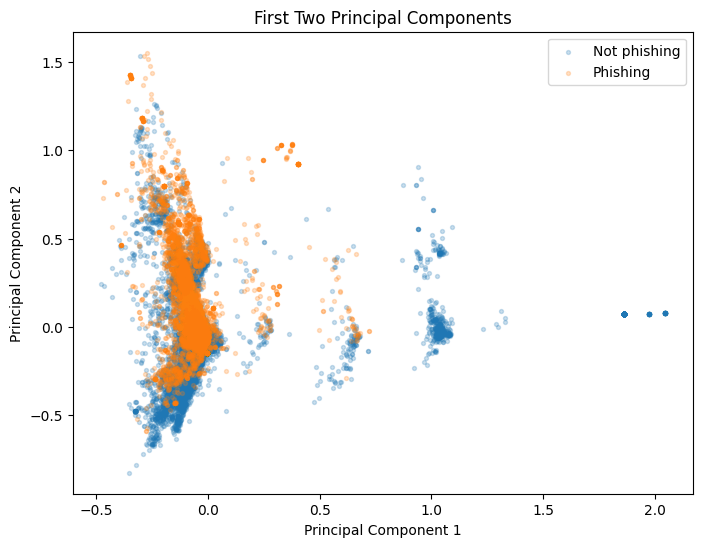

Explained variance ratios: [0.0111 0.0086]
There exists massive overlap between the phishing and non-phishing emails,
particularly around the main cluster towards the left. Interestingly, there
existed groups farther to the right that were mostly filled with non-phishing
emails. It also seemed that several phishing emails stayed concentrated a little
higher on the second component. Overall, the first two components show a few
patterns, but there isn't a clear separation of the two types of emails.


In [26]:
print("-- Q3 --")

from sklearn.decomposition import PCA

# perform PCA to reduce the dimensionality of the data
pca2 = PCA(n_components=2, svd_solver='randomized', random_state=42)
X_pca2 = pca2.fit_transform(X.to_numpy(dtype=np.float32))

# plot the first two principal components
plt.figure(figsize=(8, 6))
plt.scatter(X_pca2[y == 0, 0], X_pca2[y == 0, 1],
            label='Not phishing', alpha=0.23, s=8)
plt.scatter(X_pca2[y == 1, 0], X_pca2[y == 1, 1],
            label='Phishing', alpha=0.23, s=8)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('First Two Principal Components')
plt.legend()
plt.show()

print('Explained variance ratios:', pca2.explained_variance_ratio_.round(4))

text = "There exists massive overlap between the phishing and non-phishing emails, particularly around the main cluster towards the left. Interestingly, there existed groups farther to the right that were mostly filled with non-phishing emails. It also seemed that several phishing emails stayed concentrated a little higher on the second component. Overall, the first two components show a few patterns, but there isn't a clear separation of the two types of emails."

print("\n".join(textwrap.wrap(text, width=80)))

In [27]:
print("-- Q4 --")

# perform PCA to reduce the dimensionality of the data
pca_large = PCA(n_components=2610, svd_solver='covariance_eigh')
X_train_pca = pca_large.fit_transform(X_train.to_numpy(dtype=np.float32))
X_test_pca = pca_large.transform(X_test.to_numpy(dtype=np.float32))

# Train a linear regression model on the PCA-transformed data
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

pca_train_r2 = pca_model.score(X_train_pca, y_train)
pca_test_r2 = pca_model.score(X_test_pca, y_test)

print('PCA training R²:', round(pca_train_r2, 4))
print('PCA test R²:', round(pca_test_r2, 4))
print('Original training R²:', round(train_r2, 4))
print('Original test R²:', round(test_r2, 4))

text = "With the first 2610 principal components, the training R^2 for the regression was 0.7707 and the test R^2 was 0.6450. This training score is a bit less compared  to the original regression by 0.0006, but the test score did slightly improve by 0.0026. This indicates that removing some of the less important variation did help with overfitting, but it is a very small difference. Since we did keep 2610 out of the 2711 components, the two models overall performed similarly."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q4 --
PCA training R²: 0.7707
PCA test R²: 0.645
Original training R²: 0.7713
Original test R²: 0.6424
With the first 2610 principal components, the training R^2 for the regression
was 0.7707 and the test R^2 was 0.6450. This training score is a bit less
compared  to the original regression by 0.0006, but the test score did slightly
improve by 0.0026. This indicates that removing some of the less important
variation did help with overfitting, but it is a very small difference. Since we
did keep 2610 out of the 2711 components, the two models overall performed
similarly.


In [28]:
print("-- Q5 --")

text = "A major advantage of using principal components is that it lets us use fewer features without sacrificing too much information from the original data. In this case especially, there appear to be thousands of different words, and some of them are probably related to each other or appear together in the same emails. PCA combines original features into new components that have no correlation. This makes it easier to work with a massive dataset and does indeed help reduce overfitting. At times, even if minor, regression can also be made more speedy if substantially fewer components are kept. There is a downside, however. The components tend to be harder to interpret because they don't represent individual words anymore. There's also no accuracy improvement, since components with the most variation aren't really the most useful when it comes to predicting phishing."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q5 --
A major advantage of using principal components is that it lets us use fewer
features without sacrificing too much information from the original data. In
this case especially, there appear to be thousands of different words, and some
of them are probably related to each other or appear together in the same
emails. PCA combines original features into new components that have no
correlation. This makes it easier to work with a massive dataset and does indeed
help reduce overfitting. At times, even if minor, regression can also be made
more speedy if substantially fewer components are kept. There is a downside,
however. The components tend to be harder to interpret because they don't
represent individual words anymore. There's also no accuracy improvement, since
components with the most variation aren't really the most useful when it comes
to predicting phishing.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [29]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]